In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

# find the project folder (the one that contains the data folder)
root = Path.cwd()
while not (root / "data").exists() and root != root.parent:
    root = root.parent

DATA_DIR = root / "data" / "raw" / "EuroSAT_MS"
OUT_CSV = root / "outputs" / "ndvi_per_image.csv"

RED_BAND = 4   # B04 (rasterio counts bands from 1, so this is index 3)
NIR_BAND = 8   # B08 (index 7)


def image_ndvi(path):
    with rasterio.open(path) as f:
        red, nir = f.read([RED_BAND, NIR_BAND]).astype(np.float32)
    with np.errstate(divide="ignore", invalid="ignore"):
        ndvi = (nir - red) / (nir + red)
    ndvi = np.clip(ndvi, -1, 1)
    return np.nanmean(ndvi), np.nanstd(ndvi)


files = sorted(DATA_DIR.rglob("*.tif"))
print(len(files), "images found")

rows = []
for i, path in enumerate(files, start=1):
    mean, std = image_ndvi(path)
    rows.append({"class": path.parent.name, "file": path.name, "ndvi_mean": mean, "ndvi_std": std})
    if i % 5000 == 0:
        print(i, "/", len(files))

df = pd.DataFrame(rows)
OUT_CSV.parent.mkdir(exist_ok=True)
df.to_csv(OUT_CSV, index=False)

# sanity check: vegetation should be high, water low
print(df.groupby("class")["ndvi_mean"].mean().sort_values(ascending=False).round(3))

27000 images found
5000 / 27000
10000 / 27000
15000 / 27000
20000 / 27000
25000 / 27000
class
Forest                  0.713
Pasture                 0.654
Highway                 0.446
HerbaceousVegetation    0.385
AnnualCrop              0.376
PermanentCrop           0.372
Residential             0.340
River                   0.327
Industrial              0.223
SeaLake                -0.253
Name: ndvi_mean, dtype: float64


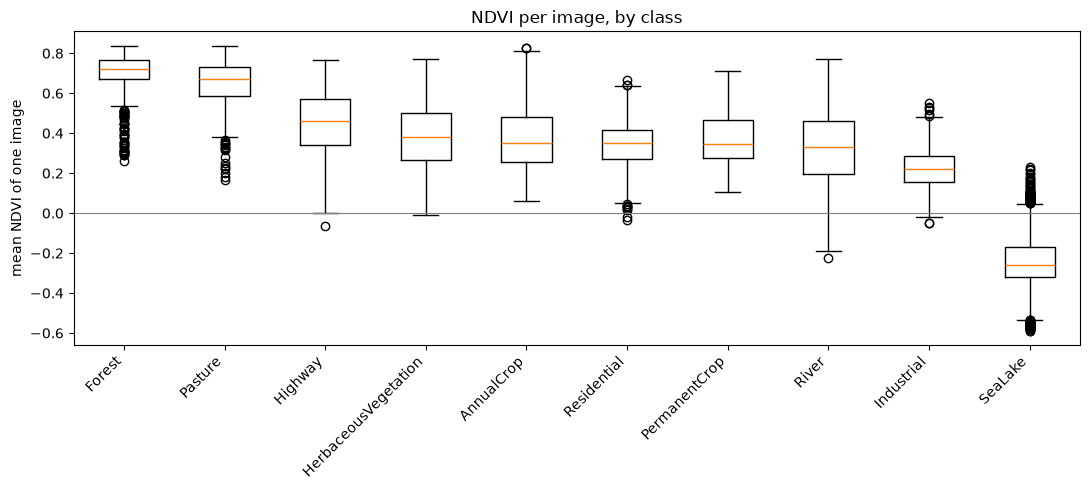

saved: reports\figures\ndvi_per_image_boxplot.png


In [5]:
import matplotlib.pyplot as plt

df = pd.read_csv(OUT_CSV)   # the table saved by the cell above

# classes ordered from highest to lowest median NDVI
order = df.groupby("class")["ndvi_mean"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([df.loc[df["class"] == c, "ndvi_mean"] for c in order])
ax.set_xticklabels(order, rotation=45, ha="right")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("mean NDVI of one image")
ax.set_title("NDVI per image, by class")

fig_path = root / "reports" / "figures" / "ndvi_per_image_boxplot.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.tight_layout()
fig.savefig(fig_path, dpi=150)
plt.show()
print("saved:", fig_path.relative_to(root))

In [6]:
from sklearn.metrics import roc_auc_score, roc_curve

df = pd.read_csv(OUT_CSV)

vegetation = ["Forest", "Pasture"]
crops = ["AnnualCrop", "PermanentCrop"]

rows = []
for veg in vegetation:
    for crop in crops:
        a = df.loc[df["class"] == veg, "ndvi_mean"]
        b = df.loc[df["class"] == crop, "ndvi_mean"]

        # label 1 = vegetation class, 0 = crop class, score = NDVI
        labels = [1] * len(a) + [0] * len(b)
        scores = list(a) + list(b)

        auc = roc_auc_score(labels, scores)
        fpr, tpr, thresholds = roc_curve(labels, scores)
        best = (tpr - fpr).argmax()   # threshold that separates the two classes best

        rows.append({
            "pair": veg + " vs " + crop,
            "median_1": round(a.median(), 3),
            "median_2": round(b.median(), 3),
            "median_difference": round(a.median() - b.median(), 3),
            "AUC": round(auc, 3),
            "best_threshold": round(thresholds[best], 3),
            "balanced_accuracy": round((tpr[best] + 1 - fpr[best]) / 2, 3),
        })

separation = pd.DataFrame(rows)
separation.to_csv(root / "outputs" / "ndvi_separation.csv", index=False)
separation

,pair,median_1,median_2,median_difference,AUC,best_threshold,balanced_accuracy
0,Forest vs AnnualCrop,0.724,0.353,0.371,0.960,0.601,0.921
1,Forest vs PermanentCrop,0.724,0.346,0.378,0.988,0.598,0.957
2,Pasture vs AnnualCrop,0.671,0.353,0.318,0.913,0.519,0.850
3,Pasture vs PermanentCrop,0.671,0.346,0.325,0.951,0.533,0.873


**Conclusion.** Per-image mean NDVI separates Forest and Pasture from the crop classes well: the median NDVI is about 0.72 (Forest) and 0.67 (Pasture) versus about 0.35 for AnnualCrop and PermanentCrop. The AUC is 0.96 and 0.99 for Forest, and 0.91 and 0.95 for Pasture, so Pasture vs AnnualCrop is the hardest pair, and a single NDVI cutoff classifies 85% to 96% of images correctly (balanced accuracy). These values are descriptive, computed on the full dataset from uncorrected reflectance, and the image distributions still overlap, so NDVI is a useful feature but not enough on its own.